# %CFE next-24h forecasting — LightGBM baseline (point + quantile)

**Goal:** forecast the hourly **carbon-free energy share (%CFE)** of a region for the next 24 hours using only **historical lags** (no weather), and set up the metrics needed to judge it and every later model (TFT etc.).

* **Target:** %CFE = 100 · (nuclear + hydro + solar + wind + geothermal [+ biomass, optional]) / total generation, per UTC hour.
* **Setup:** forecast issued every hour *t* (last observed hour), horizons *h* = 1…24, **direct strategy** (no recursion, so errors don't compound): either **one model per horizon** (default) or one **global model with the horizon as a feature** — switch with `STRATEGY`. In a first test on DE, per-horizon models were clearly better for h ≤ 12 (h=1 MAE 1.4 vs 4.1 pp; the global model under-uses the last observation) and similar or slightly worse near h = 24.
* **Data:** the repo's hourly generation mix (`data/<R>/<R>_lifecycle_emissions.csv`, 2020–2021). Split like CarbonCast: **train 2020, validation Jan–Jun 2021, test Jul–Dec 2021** (by issue time, with a 24-h gap so no target leaks across splits).
* **Models:** LightGBM point model (L2) + quantile models (5 %, 25 %, 50 %, 75 %, 95 %), compared with naive baselines.

If `lightgbm` isn't installed the notebook falls back to scikit-learn's `HistGradientBoostingRegressor` (same histogram GBDT idea, also supports quantile loss) so it still runs — install LightGBM (`pip install lightgbm`) for the real baseline.

In [1]:
import os, re, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

try:
    import lightgbm as lgb
    BACKEND = "lightgbm"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingRegressor
    BACKEND = "sklearn-hgb"
print("GBDT backend:", BACKEND)

GBDT backend: lightgbm


## 1. Parameters

In [2]:
REGION   = "DE"
DATA_DIR = None                     # None -> repo's data/; or e.g. Path("data_downloaded")
INCLUDE_BIOMASS_AS_CFE = False      # definitions differ; keep it explicit
CFE_SOURCES = ["nuclear", "hydro", "solar", "wind", "geothermal"] + (["biomass"] if INCLUDE_BIOMASS_AS_CFE else [])

HORIZON   = 24
QUANTILES = [0.05, 0.25, 0.5, 0.75, 0.95]
VAL_START, TEST_START, TEST_END = "2021-01-01", "2021-07-01", "2022-01-01"
USE_MIX_FEATURES = True             # also lag the shares of individual sources (still "historical lags")
REFIT_ON_TRAIN_VAL = True           # final model: retrain on train+val with the early-stopped number of trees
STRATEGY = "per_horizon"            # "per_horizon": one model per h (direct strategy) | "global": one model, h as feature
QUANTILE_STRATEGY = "per_horizon"   # same choice for the quantile models ("global" is 24x fewer models)
TOP_K = 6                           # decision metric: pick the k cleanest hours of the next day
CALIB_DAYS = 61                     # last part of validation held out to calibrate the quantiles (CQR)

NOTEBOOK_DIR = Path.cwd()
REPO = NOTEBOOK_DIR / "CarbonCast"
for cand in [REPO, *REPO.parents]:
    if (cand / "src").exists() and (cand / "data").exists():
        REPO = cand; break
DATA_DIR = Path(DATA_DIR) if DATA_DIR else REPO / "data"
OUT_DIR = REPO / "cfe_baseline_results"; OUT_DIR.mkdir(exist_ok=True)

## 2. Build the %CFE series

DE: 17544 hours 2020-01-01 00:00:00 -> 2021-12-31 23:00:00; CFE sources present: ['geothermal', 'hydro', 'nuclear', 'solar', 'wind']
count    17544.00
mean        49.33
std         14.86
min         15.37
25%         37.37
50%         48.65
75%         60.84
max         83.67


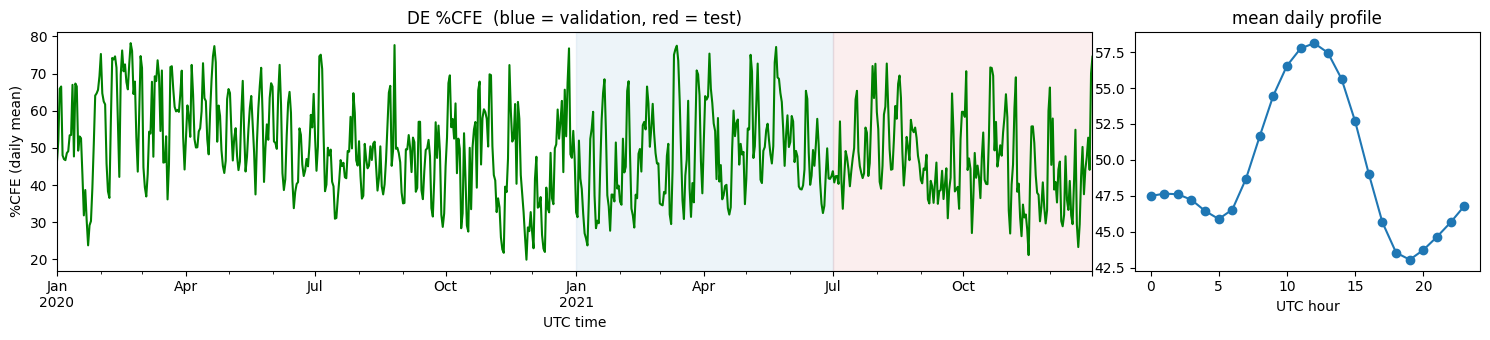

In [3]:
def load_cfe(region, data_dir=DATA_DIR, cfe_sources=CFE_SOURCES):
    f = data_dir / region / f"{region}_lifecycle_emissions.csv"
    df = pd.read_csv(f)
    df.index = pd.to_datetime(df.pop("UTC time"), utc=True).dt.tz_localize(None)   # some files carry +00:00
    src = [c for c in df.columns if c not in ("carbon_intensity",) and not c.startswith("Unnamed")]
    gen = df[src].clip(lower=0)
    gen = gen[~gen.index.duplicated()].asfreq("h")
    gen = gen.interpolate(limit=3).ffill()
    total = gen.sum(axis=1).replace(0, np.nan)
    shares = (gen.div(total, axis=0) * 100).ffill()
    cfe = shares[[c for c in src if c in cfe_sources]].sum(axis=1)
    return cfe.rename("cfe"), shares

cfe, shares = load_cfe(REGION)
print(f"{REGION}: {len(cfe)} hours {cfe.index[0]} -> {cfe.index[-1]}; CFE sources present:",
      [c for c in shares.columns if c in CFE_SOURCES])
print(cfe.describe().round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 3.5), gridspec_kw={"width_ratios": [3, 1]})
cfe.resample("D").mean().plot(ax=ax[0], color="g"); ax[0].set_ylabel("%CFE (daily mean)")
for s, e in [(VAL_START, TEST_START), (TEST_START, TEST_END)]:
    ax[0].axvspan(pd.Timestamp(s), pd.Timestamp(e), alpha=.08, color="C0" if s == VAL_START else "C3")
ax[0].set_title(f"{REGION} %CFE  (blue = validation, red = test)")
cfe.groupby(cfe.index.hour).mean().plot(ax=ax[1], marker="o"); ax[1].set_xlabel("UTC hour"); ax[1].set_title("mean daily profile")
plt.tight_layout(); plt.show()

## 3. Features (historical lags only)

For an issue time *t* and horizon *h* (target time τ = *t*+*h*):

| group | features |
|---|---|
| recent lags | %CFE at *t*, *t*−1, …, *t*−23 |
| seasonal lags of the target hour | %CFE at τ−24, τ−48, τ−72, τ−168 (all ≤ *t*, so known at issue time) |
| rolling stats | mean/std/min/max over the last 24 h, mean over the last 168 h, change vs 24 h ago |
| mix (optional) | share of each source at *t* and its 24-h mean |
| calendar | horizon *h*, hour/day-of-week/day-of-year (sin/cos) of τ, weekend flag, issue hour |

Every row only uses values observed at or before *t* — the function asserts this.

In [4]:
def make_dataset(cfe, shares, horizon=HORIZON, use_mix=USE_MIX_FEATURES):
    y = cfe.values.astype(float)
    n = len(y)
    idx = cfe.index
    t_pos = np.arange(168, n - horizon)                         # issue positions with 1 week of history
    H = np.arange(1, horizon + 1)
    T = np.repeat(t_pos, horizon); Hh = np.tile(H, len(t_pos)); TAU = T + Hh
    feats = {"h": Hh}
    for k in range(24):
        feats[f"lag_{k}"] = y[T - k]
    for k in (24, 48, 72, 168):
        assert np.all(TAU - k <= T)
        feats[f"tau_minus_{k}"] = y[TAU - k]
    s = pd.Series(y)
    roll = {"mean24": s.rolling(24).mean(), "std24": s.rolling(24).std(), "min24": s.rolling(24).min(),
            "max24": s.rolling(24).max(), "mean168": s.rolling(168).mean()}
    for name, r in roll.items():
        feats[name] = r.values[T]
    feats["diff24"] = y[T] - y[T - 24]
    if use_mix:
        for c in shares.columns:
            v = shares[c].values
            if np.nanstd(v) == 0: continue
            feats[f"share_{c}_t"] = v[T]
            feats[f"share_{c}_mean24"] = pd.Series(v).rolling(24).mean().values[T]
    tau_time, t_time = idx[TAU], idx[T]
    feats["tau_hour_sin"] = np.sin(2 * np.pi * tau_time.hour / 24); feats["tau_hour_cos"] = np.cos(2 * np.pi * tau_time.hour / 24)
    feats["tau_dow_sin"] = np.sin(2 * np.pi * tau_time.dayofweek / 7); feats["tau_dow_cos"] = np.cos(2 * np.pi * tau_time.dayofweek / 7)
    feats["tau_doy_sin"] = np.sin(2 * np.pi * tau_time.dayofyear / 365.25); feats["tau_doy_cos"] = np.cos(2 * np.pi * tau_time.dayofyear / 365.25)
    feats["tau_weekend"] = (tau_time.dayofweek >= 5).astype(int)
    feats["tau_hour"] = tau_time.hour; feats["issue_hour"] = t_time.hour
    X = pd.DataFrame(feats)
    meta = pd.DataFrame({"issue_time": t_time, "target_time": tau_time, "h": Hh, "y": y[TAU]})
    ok = ~np.isnan(meta["y"].values)
    return X[ok].reset_index(drop=True), meta[ok].reset_index(drop=True)

X, meta = make_dataset(cfe, shares)

def split_masks(meta):
    it, tt = meta["issue_time"], meta["target_time"]
    v0, t0, t1 = map(pd.Timestamp, (VAL_START, TEST_START, TEST_END))
    c0 = t0 - pd.Timedelta(days=CALIB_DAYS)
    train = (tt < v0)
    val   = (it >= v0) & (tt < t0)
    es    = (it >= v0) & (tt < c0)            # early-stopping part of validation
    calib = (it >= c0) & (tt < t0)            # calibration part of validation (never used for fitting)
    test  = (it >= t0) & (tt < t1)
    return train.values, val.values, test.values, es.values, calib.values

m_tr, m_va, m_te, m_es, m_ca = split_masks(meta)
print(f"{X.shape[1]} features | rows: train {m_tr.sum():,}  val {m_va.sum():,} "
      f"(early-stop {m_es.sum():,} + calibration {m_ca.sum():,})  test {m_te.sum():,}")

64 features | rows: train 206,484  val 103,956 (early-stop 68,820 + calibration 34,836)  test 105,408


## 4. Baselines

Any model must beat these to be useful:

* **Persistence** — the last observed value: ŷ(τ) = y(*t*).
* **Seasonal naive (24 h)** — same hour yesterday: ŷ(τ) = y(τ−24). Usually the strongest simple baseline for solar-driven regions; it's the reference for the skill scores.
* **Weekly naive** — same hour last week: ŷ(τ) = y(τ−168).
* **Seasonal naive + empirical quantiles** — a probabilistic baseline: seasonal naive plus the per-horizon quantiles of its validation errors.

In [5]:
baselines = {"persistence": X["lag_0"].values, "seasonal_naive_24h": X["tau_minus_24"].values,
             "weekly_naive": X["tau_minus_168"].values}

def empirical_quantile_baseline(point, y, h, fit_mask, quantiles=QUANTILES):
    res = pd.DataFrame({"h": h[fit_mask], "e": (y - point)[fit_mask]})
    qtab = res.groupby("h")["e"].quantile(quantiles).unstack()       # (h, q)
    return np.clip(point[:, None] + qtab.loc[h].values, 0, 100)

q_naive = empirical_quantile_baseline(baselines["seasonal_naive_24h"], meta["y"].values, meta["h"].values, m_ca)

## 5. Train LightGBM (point + quantiles)

* Point model: `objective="regression"` (L2). Quantile models: `objective="quantile", alpha=q`, one model per quantile.
* Early stopping on the validation half-year, then (optionally) refit on train + validation with that number of trees.
* Quantile models are trained on **train only** (early stopping on the first part of validation) and then **calibrated with conformalized quantile regression (CQR)** on the last `CALIB_DAYS` of validation, separately for each horizon: for each interval (q05–q95, q25–q75) the conformity score max(q̂_lo − y, y − q̂_hi) is computed on the calibration set and its finite-sample (1−α) quantile is added to both ends. GBDT quantile models are usually over-confident out of sample; CQR restores coverage with a guarantee under exchangeability. Both raw and calibrated results are reported.
* Predictions are clipped to [0, 100]. Quantile crossings are counted, then fixed by sorting (simple and standard).

In [6]:
LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=50, feature_fraction=0.8,
                  bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1, n_jobs=-1)

def fit_gbdt(Xtr, ytr, Xva, yva, objective="l2", alpha=None, refit_X=None, refit_y=None):
    if BACKEND == "lightgbm":
        params = dict(LGB_PARAMS, objective="regression" if objective == "l2" else "quantile")
        if alpha is not None: params["alpha"] = alpha
        dtr, dva = lgb.Dataset(Xtr, ytr), lgb.Dataset(Xva, yva)
        m = lgb.train(params, dtr, num_boost_round=3000, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
        best = m.best_iteration
        if refit_X is not None:
            m = lgb.train(params, lgb.Dataset(refit_X, refit_y), num_boost_round=best)
        return m, best
    # fallback: sklearn HistGradientBoosting with manual early stopping on the validation set (warm start)
    kw = dict(learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50, l2_regularization=1.0,
              early_stopping=False, random_state=0, warm_start=True, max_iter=0)
    kw.update(loss="squared_error") if objective == "l2" else kw.update(loss="quantile", quantile=alpha)
    loss = (lambda y, p: np.mean((y - p) ** 2)) if objective == "l2" else \
           (lambda y, p: np.mean(np.maximum(alpha * (y - p), (alpha - 1) * (y - p))))
    m, best, best_loss, bad = HistGradientBoostingRegressor(**kw), 0, np.inf, 0
    while m.max_iter < 1500 and bad < 4:
        m.set_params(max_iter=m.max_iter + 25); m.fit(Xtr, ytr)
        l = loss(yva, m.predict(Xva))
        if l < best_loss - 1e-9: best, best_loss, bad = m.max_iter, l, 0
        else: bad += 1
    final = HistGradientBoostingRegressor(**dict(kw, warm_start=False, max_iter=best))
    final.fit(refit_X if refit_X is not None else Xtr, refit_y if refit_y is not None else ytr)
    return final, best

def predict(m, X):
    p = m.predict(X, num_iteration=None) if BACKEND == "lightgbm" else m.predict(X)
    return np.clip(p, 0, 100)

def fit_family(X_, y_, h_, fit_m, es_m, objective, alpha=None, strategy="per_horizon", refit_m=None):
    # one model per horizon (dict h -> model) or one global model (dict 'global' -> model)
    groups = [("global", np.ones(len(y_), bool))] if strategy == "global" else [(hh, h_ == hh) for hh in range(1, HORIZON + 1)]
    models, trees = {}, {}
    for key, g_ in groups:
        a, b = fit_m & g_, es_m & g_
        r = (X_[refit_m & g_], y_[refit_m & g_]) if refit_m is not None else (None, None)
        models[key], trees[key] = fit_gbdt(X_[a], y_[a], X_[b], y_[b], objective, alpha, refit_X=r[0], refit_y=r[1])
    return models, trees

def predict_family(models, X_, h_):
    if "global" in models:
        return predict(models["global"], X_)
    out = np.empty(len(X_))
    for hh, m in models.items():
        sel = h_ == hh
        if sel.any(): out[sel] = predict(m, X_[sel])
    return out

y_all, h_all = meta["y"].values, meta["h"].values
t0 = time.time()
point_models, trees = fit_family(X, y_all, h_all, m_tr, m_va, "l2", strategy=STRATEGY,
                                 refit_m=(m_tr | m_va) if REFIT_ON_TRAIN_VAL else None)
print(f"point model(s) [{STRATEGY}]: {time.time()-t0:.0f}s, trees per model: {list(trees.values())}")
t0 = time.time()
q_models = {q: fit_family(X, y_all, h_all, m_tr, m_es, "quantile", alpha=q, strategy=QUANTILE_STRATEGY)[0]
            for q in QUANTILES}           # train only; early stopping on the non-calibration part of validation
print(f"quantile models [{QUANTILE_STRATEGY}]: {time.time()-t0:.0f}s")

def predict_quantiles(Xp, hp, q_models=q_models):
    Q = np.column_stack([predict_family(q_models[q], Xp, hp) for q in QUANTILES])
    return Q, np.mean(np.any(np.diff(Q, axis=1) < 0, axis=1))

def cqr_offsets(Q, y, h, pairs=((0.05, 0.95), (0.25, 0.75))):
    # per-horizon conformal offsets for each symmetric interval (finite-sample 1-a quantile of the conformity score)
    out = {}
    for lo, hi in pairs:
        a = 1 - (hi - lo)
        score = np.maximum(Q[:, QUANTILES.index(lo)] - y, y - Q[:, QUANTILES.index(hi)])
        off = {}
        for hh in np.unique(h):
            s_ = np.sort(score[h == hh]); n = len(s_)
            off[hh] = s_[min(n - 1, int(np.ceil((n + 1) * (1 - a))) - 1)]
        out[(lo, hi)] = off
    return out

def apply_cqr(Q, h, offsets):
    Q = Q.copy()
    for (lo, hi), off in offsets.items():
        o = np.array([off[x] for x in h])
        Q[:, QUANTILES.index(lo)] -= o; Q[:, QUANTILES.index(hi)] += o
    return np.clip(np.sort(Q, axis=1), 0, 100)

Q_cal, _ = predict_quantiles(X[m_ca], h_all[m_ca])
offsets = cqr_offsets(np.sort(Q_cal, axis=1), y_all[m_ca], h_all[m_ca])

Xte, yte, mte = X[m_te], y_all[m_te], meta[m_te].reset_index(drop=True)
pred_point = np.clip(predict_family(point_models, Xte, mte["h"].values), 0, 100)
pred_q_raw, crossing_rate = predict_quantiles(Xte, mte["h"].values)
pred_q_uncal = np.sort(pred_q_raw, axis=1)
pred_q = apply_cqr(pred_q_uncal, mte["h"].values, offsets)
print(f"quantile crossing rate before sorting: {crossing_rate:.2%}")
print("CQR offsets (pp) at h=1/12/24:", {f"{lo}-{hi}": [round(float(o[k]), 2) for k in (1, 12, 24)] for (lo, hi), o in offsets.items()})

point model(s) [per_horizon]: 16s, trees per model: [341, 199, 155, 159, 124, 116, 114, 111, 96, 105, 90, 78, 86, 71, 50, 47, 46, 51, 38, 47, 45, 33, 45, 38]
quantile models [per_horizon]: 45s
quantile crossing rate before sorting: 14.13%
CQR offsets (pp) at h=1/12/24: {'0.05-0.95': [0.28, 2.15, 1.29], '0.25-0.75': [0.07, 1.15, 1.1]}


## 6. Evaluation metrics

**Point accuracy** (percentage points of CFE): MAE, RMSE, bias (mean error — systematic over/under-forecasting), WAPE (= Σ|e| / Σy; preferred over MAPE because %CFE can be near 0 in fossil-heavy hours), R², and **skill vs seasonal naive** = 1 − MAE/MAE<sub>naive</sub> (> 0 means better than "same as yesterday").

**Probabilistic quality:**
* **Pinball (quantile) loss** per quantile and its mean — the proper score the quantile models optimise. 2 × mean pinball approximates the **CRPS**.
* **Coverage** of the 50 % (q25–q75) and 90 % (q05–q95) intervals — should be close to nominal.
* **Sharpness** — mean interval width (narrower is better, *given* correct coverage).
* **Interval (Winkler) score** for the 90 % interval — width plus a penalty for misses; combines both.
* **Reliability** — share of observations below each predicted quantile vs the quantile level.

**Decision quality** (what matters for carbon-aware scheduling), on day-ahead forecasts issued at 23:00 UTC for the next calendar day:
* **Spearman rank correlation** between forecast and actual over the 24 hours (does it order the hours correctly?).
* **Top-k hit rate** — overlap between the forecast's and the truth's k cleanest hours.
* **CFE regret** — %CFE of the truly best k hours minus that of the k hours the forecast picked (0 = perfect), and the **gain** of following the forecast vs running flat across the day.

Everything is also broken down **by horizon** — errors should grow with *h* and any good model must stay below the baselines across the curve.

In [7]:
def point_metrics(y, p, y_naive=None):
    e = p - y
    out = {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)), "Bias": np.mean(e),
           "WAPE_%": 100 * np.sum(np.abs(e)) / np.sum(np.abs(y)),
           "R2": 1 - np.sum(e**2) / np.sum((y - y.mean())**2)}
    if y_naive is not None:
        out["Skill_vs_naive24"] = 1 - out["MAE"] / np.mean(np.abs(y_naive - y))
    return out

def pinball(y, q_pred, q):
    d = y - q_pred
    return np.mean(np.maximum(q * d, (q - 1) * d))

def prob_metrics(y, Q, quantiles=QUANTILES):
    qi = {q: i for i, q in enumerate(quantiles)}
    out = {f"pinball_q{int(q*100):02d}": pinball(y, Q[:, i], q) for q, i in qi.items()}
    out["mean_pinball"] = np.mean([out[k] for k in out])
    out["CRPS_approx"] = 2 * out["mean_pinball"]
    lo50, hi50, lo90, hi90 = Q[:, qi[0.25]], Q[:, qi[0.75]], Q[:, qi[0.05]], Q[:, qi[0.95]]
    out["coverage50_%"] = 100 * np.mean((y >= lo50) & (y <= hi50))
    out["coverage90_%"] = 100 * np.mean((y >= lo90) & (y <= hi90))
    out["width50"] = np.mean(hi50 - lo50); out["width90"] = np.mean(hi90 - lo90)
    a = 0.1
    out["winkler90"] = np.mean((hi90 - lo90) + (2 / a) * (lo90 - y) * (y < lo90) + (2 / a) * (y - hi90) * (y > hi90))
    return out

def decision_metrics(meta_te, y, p, k=TOP_K, issue_hour=23):
    from scipy.stats import spearmanr
    d = meta_te.assign(y=y, p=p)
    d = d[d["issue_time"].dt.hour == issue_hour]
    rho, hit, regret, gain = [], [], [], []
    for _, g in d.groupby("issue_time"):
        if len(g) < 24: continue
        yt, pt = g["y"].values, g["p"].values
        rho.append(spearmanr(yt, pt).correlation if np.std(pt) > 0 and np.std(yt) > 0 else np.nan)
        best, pick = np.argsort(-yt)[:k], np.argsort(-pt)[:k]
        hit.append(len(set(best) & set(pick)) / k)
        regret.append(yt[best].mean() - yt[pick].mean())
        gain.append(yt[pick].mean() - yt.mean())
    return {"spearman_mean": np.nanmean(rho), f"top{k}_hit_rate": np.mean(hit),
            f"top{k}_regret_pp": np.mean(regret), f"top{k}_gain_vs_flat_pp": np.mean(gain), "n_days": len(hit)}

In [8]:
yb = {k: v[m_te] for k, v in baselines.items()}
naive = yb["seasonal_naive_24h"]
point_rows = {name: point_metrics(yte, p, naive) for name, p in yb.items()}
point_rows["LGBM_point (L2)"] = point_metrics(yte, pred_point, naive)
point_rows["LGBM_q50 (median)"] = point_metrics(yte, pred_q[:, QUANTILES.index(0.5)], naive)
point_table = pd.DataFrame(point_rows).T

prob_table = pd.DataFrame({"naive24 + empirical quantiles": prob_metrics(yte, q_naive[m_te]),
                           "LGBM quantile (raw)": prob_metrics(yte, pred_q_uncal),
                           "LGBM quantile + CQR": prob_metrics(yte, pred_q)}).T
prob_table["crossing_rate_%"] = [np.nan, 100 * crossing_rate, 0.0]

dec_rows = {name: decision_metrics(mte, yte, p) for name, p in yb.items() if name != "persistence"}  # flat -> ranking undefined
dec_rows["LGBM_point (L2)"] = decision_metrics(mte, yte, pred_point)
dec_rows["LGBM_q50 (median)"] = decision_metrics(mte, yte, pred_q[:, QUANTILES.index(0.5)])
dec_table = pd.DataFrame(dec_rows).T

print(f"=== {REGION} | test {TEST_START} -> {TEST_END} | backend {BACKEND} ===")
print("\nPoint metrics (percentage points of CFE)"); display(point_table.round(3))
print("\nProbabilistic metrics"); display(prob_table.round(3))
print(f"\nDecision metrics (day-ahead, issued 23:00 UTC, k={TOP_K})"); display(dec_table.round(3))

=== DE | test 2021-07-01 -> 2022-01-01 | backend lightgbm ===

Point metrics (percentage points of CFE)


,MAE,RMSE,Bias,WAPE_%,R2,Skill_vs_naive24
persistence,9.318,12.244,-0.081,20.129,0.188,-0.012
seasonal_naive_24h,9.206,11.990,-0.155,19.887,0.221,0.000
weekly_naive,12.125,15.545,-0.360,26.192,-0.309,-0.317
LGBM_point (L2),6.448,8.621,0.040,13.930,0.598,0.300
LGBM_q50 (median),6.639,8.843,0.377,14.342,0.577,0.279



Probabilistic metrics


,pinball_q05,pinball_q25,pinball_q50,pinball_q75,pinball_q95,mean_pinball,CRPS_approx,coverage50_%,coverage90_%,width50,width90,winkler90,crossing_rate_%
naive24 + empirical quantiles,1.366,3.801,4.605,3.794,1.294,2.972,5.944,42.460,85.623,11.547,34.896,53.204,NaN
LGBM quantile (raw),0.847,2.545,3.320,2.798,0.988,2.099,4.199,40.922,84.534,9.010,26.537,36.699,14.126
LGBM quantile + CQR,0.849,2.518,3.320,2.774,0.949,2.082,4.164,47.998,89.764,10.684,29.449,35.952,0.000



Decision metrics (day-ahead, issued 23:00 UTC, k=6)


,spearman_mean,top6_hit_rate,top6_regret_pp,top6_gain_vs_flat_pp,n_days
seasonal_naive_24h,0.450,0.599,3.609,5.911,183.0
weekly_naive,0.510,0.623,2.927,6.593,183.0
LGBM_point (L2),0.551,0.644,2.532,6.988,183.0
LGBM_q50 (median),0.556,0.625,2.613,6.907,183.0


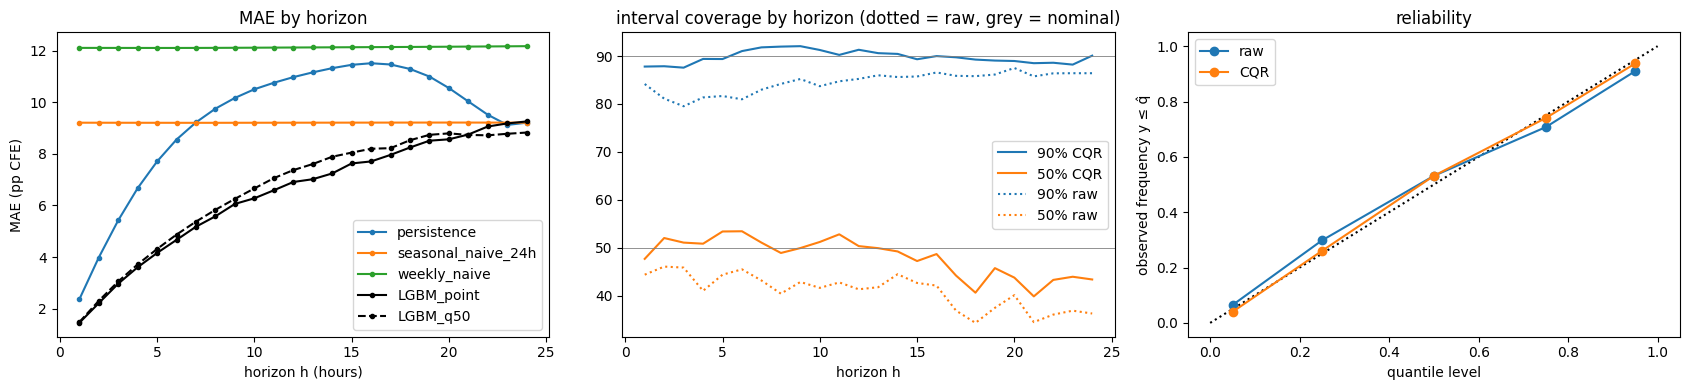

In [9]:
by_h = pd.DataFrame({name: pd.Series(np.abs(p - yte)).groupby(mte["h"].values).mean()
                     for name, p in {**yb, "LGBM_point": pred_point, "LGBM_q50": pred_q[:, 2]}.items()})
qi = {q: i for i, q in enumerate(QUANTILES)}
def cov_by_h(Q, lo, hi):
    return pd.Series((yte >= Q[:, qi[lo]]) & (yte <= Q[:, qi[hi]])).groupby(mte["h"].values).mean() * 100
cov_h = pd.DataFrame({"90% CQR": cov_by_h(pred_q, .05, .95), "50% CQR": cov_by_h(pred_q, .25, .75),
                      "90% raw": cov_by_h(pred_q_uncal, .05, .95), "50% raw": cov_by_h(pred_q_uncal, .25, .75)})
reliab = pd.DataFrame({"raw": {q: np.mean(yte <= pred_q_uncal[:, i]) for q, i in qi.items()},
                       "CQR": {q: np.mean(yte <= pred_q[:, i]) for q, i in qi.items()}})

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
by_h.plot(ax=ax[0], marker=".", style={"LGBM_point": "k-", "LGBM_q50": "k--"}); ax[0].set_xlabel("horizon h (hours)")
ax[0].set_ylabel("MAE (pp CFE)"); ax[0].set_title("MAE by horizon")
cov_h.plot(ax=ax[1], style=["C0-", "C1-", "C0:", "C1:"]); ax[1].axhline(90, color="grey", lw=.6); ax[1].axhline(50, color="grey", lw=.6)
ax[1].set_title("interval coverage by horizon (dotted = raw, grey = nominal)"); ax[1].set_xlabel("horizon h")
ax[2].plot([0, 1], [0, 1], "k:"); reliab.plot(ax=ax[2], marker="o")
ax[2].set_xlabel("quantile level"); ax[2].set_ylabel("observed frequency y ≤ q̂"); ax[2].set_title("reliability")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{REGION}_metrics.png", dpi=110); plt.show()

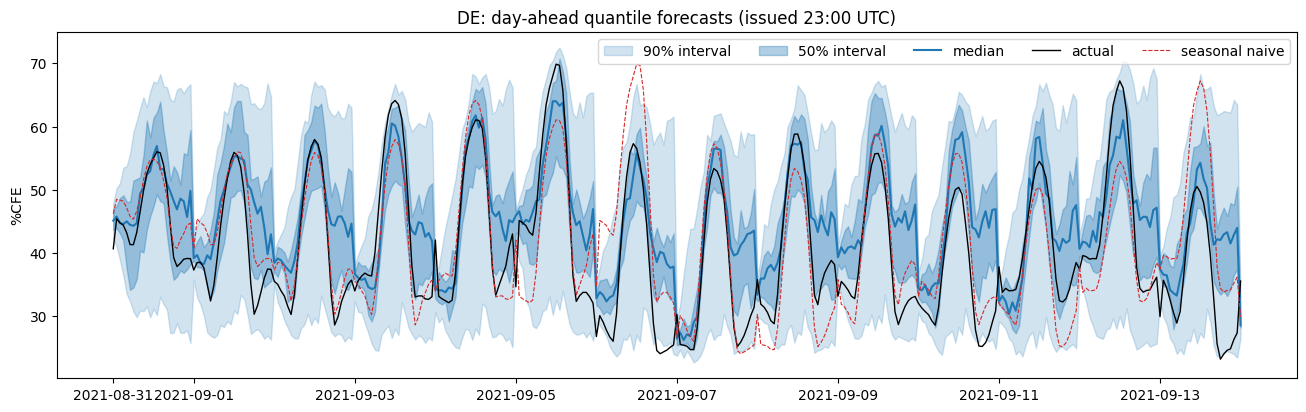

In [10]:
# Fan chart: day-ahead forecasts (issued 23:00 UTC) stitched over two test weeks
d = mte.assign(p=pred_point, **{f"q{int(q*100):02d}": pred_q[:, i] for q, i in qi.items()})
d = d[d["issue_time"].dt.hour == 23].set_index("target_time").sort_index()
win = d.loc[d.index[0] + pd.Timedelta(days=60): d.index[0] + pd.Timedelta(days=74)]
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.fill_between(win.index, win.q05, win.q95, alpha=.2, color="C0", label="90% interval")
ax.fill_between(win.index, win.q25, win.q75, alpha=.35, color="C0", label="50% interval")
ax.plot(win.index, win.q50, color="C0", label="median"); ax.plot(win.index, win.y, "k", lw=1, label="actual")
ax.plot(win.index, cfe.shift(24).reindex(win.index), color="C3", lw=.8, ls="--", label="seasonal naive")
ax.set_ylabel("%CFE"); ax.set_title(f"{REGION}: day-ahead quantile forecasts (issued 23:00 UTC)"); ax.legend(ncol=5)
plt.savefig(OUT_DIR / f"{REGION}_fan_chart.png", dpi=110); plt.show()

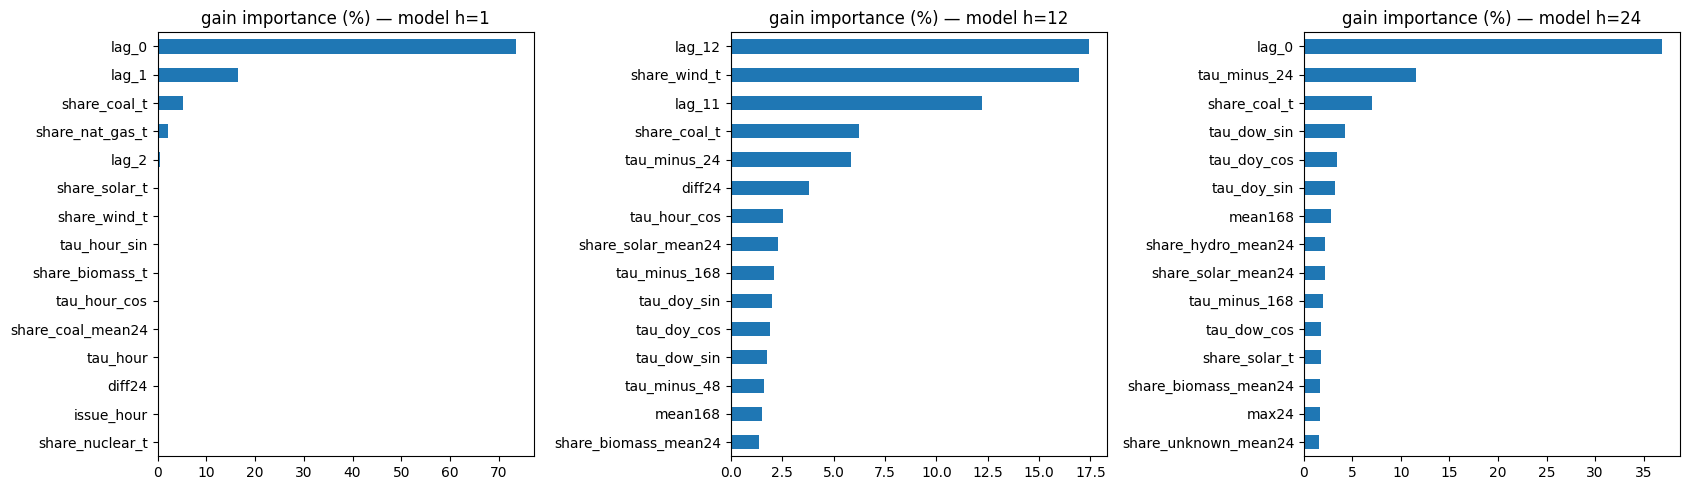

In [11]:
if BACKEND == "lightgbm":
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    keys = ["global"] if "global" in point_models else [1, 12, 24]
    for ax, k in zip(axes, keys):
        imp = pd.Series(point_models[k].feature_importance("gain"), index=X.columns).sort_values(ascending=False)
        (imp.head(15) / imp.sum() * 100).iloc[::-1].plot.barh(ax=ax, title=f"gain importance (%) — model h={k}")
    plt.tight_layout(); plt.show()
else:
    print("Feature importance plot needs LightGBM (pip install lightgbm).")

## 7. Save results

In [ ]:
point_table.to_csv(OUT_DIR / f"{REGION}_point_metrics.csv")
prob_table.to_csv(OUT_DIR / f"{REGION}_prob_metrics.csv")
dec_table.to_csv(OUT_DIR / f"{REGION}_decision_metrics.csv")
by_h.to_csv(OUT_DIR / f"{REGION}_mae_by_horizon.csv")
mte.assign(pred_point=pred_point, **{f"q{int(q*100):02d}": pred_q[:, i] for q, i in qi.items()}) \
   .to_csv(OUT_DIR / f"{REGION}_test_predictions.csv", index=False)
print("saved to", OUT_DIR)

## 8. (Optional) All regions

Runs the full pipeline for every region in `data/` and collects the headline numbers.

In [13]:
def run_region(region, strategy=STRATEGY, q_strategy=QUANTILE_STRATEGY):
    c, sh = load_cfe(region)
    X_, m_ = make_dataset(c, sh)
    tr, va, te, es, ca = split_masks(m_)
    y_, h_ = m_["y"].values, m_["h"].values
    pm, _ = fit_family(X_, y_, h_, tr, va, "l2", strategy=strategy, refit_m=(tr | va) if REFIT_ON_TRAIN_VAL else None)
    qm = {q: fit_family(X_, y_, h_, tr, es, "quantile", alpha=q, strategy=q_strategy)[0] for q in QUANTILES}
    off = cqr_offsets(np.sort(predict_quantiles(X_[ca], h_[ca], qm)[0], axis=1), y_[ca], h_[ca])
    pp = np.clip(predict_family(pm, X_[te], h_[te]), 0, 100)
    Q = apply_cqr(np.sort(predict_quantiles(X_[te], h_[te], qm)[0], axis=1), h_[te], off)
    yt, nv, mt = y_[te], X_["tau_minus_24"].values[te], m_[te].reset_index(drop=True)
    pt, pr = point_metrics(yt, pp, nv), prob_metrics(yt, Q)
    dc, dn = decision_metrics(mt, yt, pp), decision_metrics(mt, yt, nv)
    mae_h = pd.Series(np.abs(pp - yt)).groupby(h_[te]).mean()
    return {"mean_CFE_%": yt.mean(), "MAE_persist": np.mean(np.abs(X_["lag_0"].values[te] - yt)),
            "MAE_naive24": np.mean(np.abs(nv - yt)), "MAE_LGBM": pt["MAE"], "skill_vs_naive24": pt["Skill_vs_naive24"],
            "MAE_h1": mae_h[1], "MAE_h24": mae_h[24], "bias": pt["Bias"],
            "CRPS_approx": pr["CRPS_approx"], "cov50_%": pr["coverage50_%"], "cov90_%": pr["coverage90_%"],
            "width90": pr["width90"], "spearman_naive24": dn["spearman_mean"], "spearman_LGBM": dc["spearman_mean"],
            f"top{TOP_K}_regret_naive24": dn[f"top{TOP_K}_regret_pp"], f"top{TOP_K}_regret_LGBM": dc[f"top{TOP_K}_regret_pp"]}


regions = sorted(p.name for p in DATA_DIR.iterdir() if (p / f"{p.name}_lifecycle_emissions.csv").exists())
rows = {}
for r in regions:
    t0 = time.time(); rows[r] = run_region(r); print(f"{r}: {time.time()-t0:.0f}s")
summary = pd.DataFrame(rows).T.round(3)
summary.to_csv(OUT_DIR / "all_regions_summary.csv"); display(summary)

AUS_QLD: 67s
BPAT: 69s
CISO: 70s
DE: 58s
ERCO: 45s
ES: 66s
FPL: 72s
ISNE: 68s
NL: 45s
NYISO: 47s
PJM: 59s
PL: 44s
SE: 115s


,mean_CFE_%,MAE_persist,MAE_naive24,MAE_LGBM,skill_vs_naive24,MAE_h1,MAE_h24,bias,CRPS_approx,cov50_%,cov90_%,width90,spearman_naive24,spearman_LGBM,top6_regret_naive24,top6_regret_LGBM
AUS_QLD,18.447,15.778,3.036,2.663,0.123,1.217,2.889,-0.755,1.762,41.671,84.720,10.714,0.865,0.878,0.580,0.320
BPAT,88.094,1.948,1.300,1.311,-0.008,0.406,1.687,0.848,0.921,38.695,81.245,6.075,0.622,0.650,0.500,0.569
CISO,44.218,14.261,5.355,4.155,0.224,1.679,4.917,-0.091,2.671,50.446,89.322,18.359,0.833,0.855,0.468,0.361
DE,46.291,9.318,9.206,6.448,0.300,1.451,9.254,0.040,4.164,47.998,89.764,29.449,0.450,0.551,3.609,2.532
ERCO,37.801,9.372,9.578,7.097,0.259,1.317,8.975,0.194,4.572,45.391,83.866,30.653,0.484,0.595,3.947,2.571
ES,64.091,6.464,6.321,4.926,0.221,1.392,6.223,1.244,3.372,43.947,82.115,20.799,0.618,0.663,1.486,1.314
FPL,26.261,5.137,1.915,1.626,0.151,0.666,1.873,-0.200,1.159,51.855,86.384,7.545,0.872,0.892,1.050,0.886
ISNE,35.874,4.982,3.902,3.497,0.104,0.995,4.411,1.064,2.273,43.166,86.960,15.487,0.669,0.694,0.942,0.697
NL,18.726,6.454,8.436,5.911,0.299,1.085,8.200,-1.215,3.733,54.280,90.505,25.115,0.221,0.383,4.943,2.796
NYISO,45.497,4.142,3.568,3.531,0.010,1.654,4.202,1.554,2.990,45.098,81.844,15.137,0.612,0.664,1.304,0.966
